In [2]:
!nvidia-smi

Sun Nov  8 17:20:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!apt-get -qq install -y openslide-tools
!pip -q install openslide-python scikit-image awscli

Selecting previously unselected package libopenslide0.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libopenslide0_3.4.1+dfsg-7build2_amd64.deb ...
Unpacking libopenslide0 (3.4.1+dfsg-7build2) ...
Selecting previously unselected package openslide-tools.
Preparing to unpack .../openslide-tools_3.4.1+dfsg-7build2_amd64.deb ...
Unpacking openslide-tools (3.4.1+dfsg-7build2) ...
Setting up libopenslide0 (3.4.1+dfsg-7build2) ...
Setting up openslide-tools (3.4.1+dfsg-7build2) ...
Processing triggers for man-db (2.12.0-4build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm_debug.so.1 is n

In [4]:
from google.colab import drive
import os
drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/cam', exist_ok=True)
os.makedirs('/content/data', exist_ok=True)
%cd /content/drive/MyDrive/cam

Mounted at /content/drive
/content/drive/MyDrive/cam


In [5]:
%%writefile preprocess.py
import argparse, os
import numpy as np, cv2, openslide, pandas as pd
import xml.etree.ElementTree as ET
from tqdm import tqdm

PATCH = 256

def tissue_mask(img):
    s = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[:, :, 1]
    s = cv2.GaussianBlur(s, (5, 5), 0)
    _, m = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    return m > 0

def tumor_mask(xml_path, shape, ds):
    m = np.zeros(shape, np.uint8)
    if not isinstance(xml_path, str) or not xml_path:
        return m
    tumor, excl = [], []
    for ann in ET.parse(xml_path).getroot().iter("Annotation"):
        pts = np.array([[float(c.get("X")), float(c.get("Y"))]
                        for c in ann.iter("Coordinate")]) / ds
        if len(pts) < 3: continue
        (excl if ann.get("PartOfGroup") == "_2" else tumor).append(pts.astype(np.int32))
    if tumor: cv2.fillPoly(m, tumor, 1)
    if excl:  cv2.fillPoly(m, excl, 0)
    return m

def process(r, a):
    slide = openslide.OpenSlide(r.path)
    ml = slide.get_best_level_for_downsample(32)
    mds = slide.level_downsamples[ml]
    W, H = slide.level_dimensions[ml]
    img = np.array(slide.read_region((0, 0), ml, (W, H)).convert("RGB"))
    tis = tissue_mask(img)
    tum = tumor_mask(r.xml, tis.shape, mds)
    l1 = slide.get_best_level_for_downsample(2)          # 20x, assuming level 0 is 40x
    ds1 = slide.level_downsamples[l1]
    size0 = int(PATCH * ds1)                              # patch size in level-0 pixels
    step = int(a.stride * ds1)
    W0, H0 = slide.dimensions
    coords, labels = [], []
    for y in range(0, H0 - size0, step):
        for x in range(0, W0 - size0, step):
            x1, y1 = int(x / mds), int(y / mds)
            x2, y2 = max(x1 + 1, int((x + size0) / mds)), max(y1 + 1, int((y + size0) / mds))
            if tis[y1:y2, x1:x2].mean() < a.min_tissue: continue
            coords.append((x, y))
            labels.append(int(tum[y1:y2, x1:x2].mean() > a.tumor_frac))
    np.savez_compressed(f"{a.out}/{r.slide_id}.npz", coords=np.array(coords).reshape(-1, 2),
                        labels=np.array(labels), size0=size0, mds=mds, tumor=tum)
    return len(coords), int(sum(labels))

if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--manifest", default="manifest.csv")
    p.add_argument("--out", default="patches")
    p.add_argument("--stride", type=int, default=256)    # in 20x pixels; 512 = 4x fewer patches
    p.add_argument("--min_tissue", type=float, default=0.5)
    p.add_argument("--tumor_frac", type=float, default=0.5)
    a = p.parse_args()
    os.makedirs(a.out, exist_ok=True)
    df = pd.read_csv(a.manifest)
    for r in tqdm(df.itertuples(), total=len(df)):
        if os.path.exists(f"{a.out}/{r.slide_id}.npz"): continue
        n, t = process(r, a)
        tqdm.write(f"{r.slide_id}: {n} patches, {t} tumor")

Writing preprocess.py


In [6]:
%%writefile extract_features.py
import argparse, os
import numpy as np, pandas as pd, torch, torch.nn as nn, torchvision, openslide
import torchvision.transforms as T
from PIL import Image
from skimage.color import rgb2hed, hed2rgb
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

PATCH = 256

def hed_jitter(img, sigma=0.05):
    hed = rgb2hed(np.asarray(img))
    hed = hed * np.random.uniform(1 - sigma, 1 + sigma, 3) + np.random.uniform(-sigma, sigma, 3)
    out = np.clip(hed2rgb(hed), 0, 1)
    return Image.fromarray((out * 255).astype(np.uint8))

class Bag(Dataset):
    def __init__(self, path, coords, jitter):
        self.path, self.coords, self.jitter, self.slide = path, coords, jitter, None
        s = openslide.OpenSlide(path)
        self.lv = [s.get_best_level_for_downsample(d) for d in (2, 4)]   # 20x, 10x
        self.ds = [s.level_downsamples[l] for l in self.lv]
        self.tf = T.Compose([T.ToTensor(),
                             T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    def __len__(self): return len(self.coords)
    def __getitem__(self, i):
        if self.slide is None: self.slide = openslide.OpenSlide(self.path)  # one handle per worker
        x, y = self.coords[i]
        cx, cy = x + PATCH * self.ds[0] / 2, y + PATCH * self.ds[0] / 2     # shared center
        out = []
        for l, d in zip(self.lv, self.ds):
            half = PATCH * d / 2
            img = self.slide.read_region((int(cx - half), int(cy - half)), l, (PATCH, PATCH)).convert("RGB")
            if self.jitter: img = hed_jitter(img)
            out.append(self.tf(img))
        return torch.stack(out)

if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--manifest", default="manifest.csv")
    p.add_argument("--patches", default="patches")
    p.add_argument("--out", default="feats")
    p.add_argument("--jitter", action="store_true")
    p.add_argument("--bs", type=int, default=64)
    p.add_argument("--workers", type=int, default=8)
    a = p.parse_args()
    os.makedirs(a.out, exist_ok=True)

    model = torchvision.models.resnet50(weights="IMAGENET1K_V2")
    model.fc = nn.Identity()
    model = model.cuda().eval()

    df = pd.read_csv(a.manifest)
    for r in tqdm(df.itertuples(), total=len(df)):
        out = f"{a.out}/{r.slide_id}.pt"
        pf = f"{a.patches}/{r.slide_id}.npz"
        if os.path.exists(out) or not os.path.exists(pf): continue
        meta = np.load(pf)
        if len(meta["coords"]) == 0: continue
        dl = DataLoader(Bag(r.path, meta["coords"], a.jitter), batch_size=a.bs, num_workers=a.workers)
        f20, f10 = [], []
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            for b in dl:
                n = b.shape[0]
                f = model(b.cuda(non_blocking=True).flatten(0, 1)).view(n, 2, -1)
                f20.append(f[:, 0].half().cpu()); f10.append(f[:, 1].half().cpu())
        torch.save({"f20": torch.cat(f20), "f10": torch.cat(f10),
                    "labels": torch.tensor(meta["labels"])}, out)

Writing extract_features.py


In [7]:
%%writefile train_patch.py
import argparse, os
import pandas as pd, torch, torch.nn as nn
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score

def load(df, feats, keys):
    X, Y = [], []
    for sid in df.slide_id:
        p = f"{feats}/{sid}.pt"
        if not os.path.exists(p): continue
        d = torch.load(p)
        X.append(torch.cat([d[k] for k in keys], 1)); Y.append(d["labels"])
    return torch.cat(X), torch.cat(Y).float()

p = argparse.ArgumentParser()
p.add_argument("--manifest", default="manifest.csv")
p.add_argument("--feats", default="feats")
p.add_argument("--epochs", type=int, default=10)
a = p.parse_args()
df = pd.read_csv(a.manifest)
tr, te = df[df.split == "train"], df[df.split == "test"]

for name, keys in [("20x", ["f20"]), ("10x", ["f10"]), ("20x+10x", ["f20", "f10"])]:
    Xtr, Ytr = load(tr, a.feats, keys); Xte, Yte = load(te, a.feats, keys)
    mu, sd = Xtr.float().mean(0), Xtr.float().std(0) + 1e-6
    clf = nn.Linear(Xtr.shape[1], 1).cuda()
    opt = torch.optim.Adam(clf.parameters(), 1e-3)
    lossf = nn.BCEWithLogitsLoss(pos_weight=((Ytr == 0).sum() / (Ytr == 1).sum().clamp(min=1)).cuda())
    for ep in range(a.epochs):
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), 4096):
            idx = perm[i:i + 4096]
            x = ((Xtr[idx].float() - mu) / sd).cuda(); y = Ytr[idx].cuda()
            opt.zero_grad(); lossf(clf(x).squeeze(1), y).backward(); opt.step()
    with torch.no_grad():
        pr = torch.cat([torch.sigmoid(clf(((Xte[i:i+8192].float() - mu) / sd).cuda()).squeeze(1)).cpu()
                        for i in range(0, len(Xte), 8192)]).numpy()
    yt = Yte.numpy()
    print(f"{name}: n_test={len(yt)} pos={int(yt.sum())} "
          f"acc={accuracy_score(yt, pr > .5):.4f} auc={roc_auc_score(yt, pr):.4f} f1={f1_score(yt, pr > .5):.4f}")

Writing train_patch.py


In [8]:
%%writefile train_mil.py
import argparse, copy, json, os
import numpy as np, pandas as pd, torch, torch.nn as nn
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.model_selection import train_test_split

class ABMIL(nn.Module):
    def __init__(s, d_in, d=512, h=256):
        super().__init__()
        s.fc = nn.Sequential(nn.Linear(d_in, d), nn.ReLU(), nn.Dropout(0.25))
        s.V, s.U, s.w, s.cls = nn.Linear(d, h), nn.Linear(d, h), nn.Linear(h, 1), nn.Linear(d, 1)
    def forward(s, x):
        h = s.fc(x)
        a = torch.softmax(s.w(torch.tanh(s.V(h)) * torch.sigmoid(s.U(h))).squeeze(-1), 0)
        return s.cls((a.unsqueeze(-1) * h).sum(0)).squeeze(), a

def load_bags(df, feats, mode):
    bags = {}
    for r in df.itertuples():
        p = f"{feats}/{r.slide_id}.pt"
        if not os.path.exists(p): continue
        d = torch.load(p)
        x = {"single": d["f20"], "f10": d["f10"], "multi": torch.cat([d["f20"], d["f10"]], 1)}[mode]
        bags[r.slide_id] = (x, r.label)
    return bags

def evaluate(model, bags):
    model.eval(); ys, ps, att = [], [], {}
    with torch.no_grad():
        for sid, (x, y) in bags.items():
            logit, a = model(x.cuda().float())
            ys.append(y); ps.append(torch.sigmoid(logit).item()); att[sid] = a.cpu().numpy()
    return ys, ps, att

p = argparse.ArgumentParser()
p.add_argument("--manifest", default="manifest.csv")
p.add_argument("--feats", default="feats")
p.add_argument("--mode", default="single", choices=["single", "multi", "f10"])
p.add_argument("--tag", default=None)
p.add_argument("--epochs", type=int, default=40)
p.add_argument("--seed", type=int, default=0)
a = p.parse_args()
tag = a.tag or f"{a.feats}_{a.mode}"
torch.manual_seed(a.seed); np.random.seed(a.seed)

df = pd.read_csv(a.manifest)
trdf, vadf = train_test_split(df[df.split == "train"], test_size=0.2, stratify=df[df.split == "train"].label, random_state=a.seed)
tedf = df[df.split == "test"]
train, val, test = [load_bags(d, a.feats, a.mode) for d in (trdf, vadf, tedf)]
d_in = next(iter(train.values()))[0].shape[1]

model = ABMIL(d_in).cuda()
opt = torch.optim.Adam(model.parameters(), 2e-4, weight_decay=1e-4)
lossf = nn.BCEWithLogitsLoss()
best, best_state = -1, None
for ep in range(a.epochs):
    model.train()
    for sid in np.random.permutation(list(train)):
        x, y = train[sid]
        logit, _ = model(x.cuda().float())
        loss = lossf(logit, torch.tensor(float(y)).cuda())
        opt.zero_grad(); loss.backward(); opt.step()
    ys, ps, _ = evaluate(model, val)
    auc = roc_auc_score(ys, ps)
    if auc > best: best, best_state = auc, copy.deepcopy(model.state_dict())
    print(f"epoch {ep} val_auc {auc:.3f}")

model.load_state_dict(best_state)
ys, ps, att = evaluate(model, test)
res = dict(tag=tag, seed=a.seed, val_auc=best, test_auc=roc_auc_score(ys, ps),
           test_acc=accuracy_score(ys, np.array(ps) > 0.5), n_test=len(ys))
print(res)
os.makedirs("results", exist_ok=True); os.makedirs(f"results/attn_{tag}", exist_ok=True)
json.dump(res, open(f"results/{tag}_s{a.seed}.json", "w"))
pd.DataFrame(dict(slide_id=list(test), y=ys, p=ps)).to_csv(f"results/preds_{tag}_s{a.seed}.csv", index=False)
for sid, v in att.items(): np.save(f"results/attn_{tag}/{sid}.npy", v)

Writing train_mil.py


In [9]:
%%writefile heatmap.py
import sys, numpy as np, pandas as pd, openslide, matplotlib
matplotlib.use("Agg"); import matplotlib.pyplot as plt
sid, tag = sys.argv[1], sys.argv[2]            # e.g. test_001 feats_multi
r = pd.read_csv("manifest.csv").set_index("slide_id").loc[sid]
s = openslide.OpenSlide(r.path)
meta = np.load(f"patches/{sid}.npz"); ds = float(meta["mds"])
lvl = s.get_best_level_for_downsample(32)
thumb = np.array(s.read_region((0, 0), lvl, s.level_dimensions[lvl]).convert("RGB"))
a = np.load(f"results/attn_{tag}/{sid}.npy"); a = a / a.max()
heat, sz = np.zeros(thumb.shape[:2], np.float32), max(1, int(meta["size0"] / ds))
for (x, y), w in zip(meta["coords"], a):
    heat[int(y / ds):int(y / ds) + sz, int(x / ds):int(x / ds) + sz] = w
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(thumb); ax[0].set_title("slide")
ax[1].imshow(thumb); ax[1].imshow(heat, alpha=0.5, cmap="jet"); ax[1].set_title("attention")
ax[2].imshow(meta["tumor"], cmap="gray"); ax[2].set_title("annotation")
for x in ax: x.axis("off")
plt.tight_layout(); plt.savefig(f"results/heatmap_{sid}_{tag}.png", dpi=150)

Writing heatmap.py


In [10]:
!ls -la

total 41
drwx------  2 root root  4096 Nov  8 17:22 .
drwx------ 29 root root  4096 Nov  8 17:22 ..
-rw-------  1 root root  3056 Nov  8 17:22 extract_features.py
-rw-------  1 root root  1094 Nov  8 17:22 heatmap.py
-rw-------  1 root root  2920 Nov  8 17:22 preprocess.py
-rw-------  1 root root 20383 Nov  8 17:22 run.ipynb
-rw-------  1 root root  3256 Nov  8 17:22 train_mil.py
-rw-------  1 root root  1826 Nov  8 17:22 train_patch.py


In [11]:
!aws s3 ls --no-sign-request s3://camelyon-dataset/CAMELYON16/images/ | head -5
!aws s3 ls --no-sign-request s3://camelyon-dataset/CAMELYON16/ --recursive | grep -i -E "reference|\.csv|readme"

2022-09-28 09:16:56 1255854916 normal_001.tif
2022-09-28 09:17:06 1570273574 normal_002.tif
2022-09-28 09:17:38 2160066168 normal_003.tif
2022-09-28 09:17:51  990100952 normal_004.tif
2022-09-28 09:17:51 1524383906 normal_005.tif

[Errno 32] Broken pipe
Exception ignored on flushing sys.stdout:
BrokenPipeError: [Errno 32] Broken pipe
2022-09-28 09:16:24       3642 CAMELYON16/README.md
2022-09-28 09:16:56        186 CAMELYON16/evaluation/example.csv
2022-09-28 09:16:56      12182 CAMELYON16/evaluation/reference.csv


In [12]:
!aws s3 cp --no-sign-request s3://camelyon-dataset/CAMELYON16/evaluation/reference.csv reference.csv
!head -3 reference.csv

download: s3://camelyon-dataset/CAMELYON16/evaluation/reference.csv to ./reference.csv
image,type,class,center
normal_001.tif,normal,negative,0
normal_002.tif,normal,negative,0


In [13]:
!aws s3 ls --no-sign-request s3://camelyon-dataset/CAMELYON16/images/ | grep -E "test_001|tumor_001"

2022-09-28 10:30:34 1142160268 test_001.tif
2022-09-28 11:26:56 3264779514 tumor_001.tif


In [17]:
!head -3 reference.csv

image,type,class,center
normal_001.tif,normal,negative,0
normal_002.tif,normal,negative,0


In [18]:
import pandas as pd
ref = {}
for line in open("reference.csv"):
    p = line.strip().split(",")
    if len(p) >= 2:
        sid = p[0].strip().strip('"').lower().replace(".tif", "")
        if sid.startswith("test"):
            ref[sid] = int(p[1].strip().strip('"').lower() == "tumor")
print("labels loaded:", len(ref), "tumor:", sum(ref.values()))
assert len(ref) > 100, "reference.csv did not parse, check head -3 output"

rows = []
for i in range(1, 21): rows.append((f"tumor_{i:03d}", "train", 1))
for i in range(1, 21): rows.append((f"normal_{i:03d}", "train", 0))
for i in range(1, 31):
    sid = f"test_{i:03d}"
    rows.append((sid, "test", ref[sid]))
df = pd.DataFrame(rows, columns=["slide_id", "split", "label"])
df["path"] = "/content/data/" + df.slide_id + ".tif"
df["xml"] = ""
df.to_csv("manifest.csv", index=False)
print(df.groupby(["split", "label"]).size())

labels loaded: 129 tumor: 49
split  label
test   0        17
       1        13
train  0        20
       1        20
dtype: int64


In [20]:
import subprocess, os, pandas as pd
B = "s3://camelyon-dataset/CAMELYON16"
def sh(c): subprocess.run(c, shell=True, check=True)

df = pd.read_csv("manifest.csv")
LIMIT = 1                      # change to len(df) after the test run
for r in df.head(LIMIT).itertuples():
    sid = r.slide_id
    if os.path.exists(f"feats/{sid}.pt"): continue
    sh(f"aws s3 cp --no-sign-request {B}/images/{sid}.tif /content/data/{sid}.tif --only-show-errors")
    sh(f"aws s3 cp --no-sign-request {B}/annotations/{sid}.xml /content/data/{sid}.xml --only-show-errors || true")
    xml = f"/content/data/{sid}.xml"
    pd.DataFrame([dict(slide_id=sid, path=f"/content/data/{sid}.tif",
                       xml=xml if os.path.exists(xml) else "",
                       split=r.split, label=r.label)]).to_csv("one.csv", index=False)
    sh("python preprocess.py --manifest one.csv --stride 512")
    sh("python extract_features.py --manifest one.csv --workers 2")
    sh(f"rm -f /content/data/{sid}.*")

In [21]:
!ls -lh feats patches

import numpy as np, torch
m = np.load("patches/tumor_001.npz")
print(len(m["coords"]), "patches,", int(m["labels"].sum()), "tumor")
d = torch.load("feats/tumor_001.pt")
print(d["f20"].shape, d["f10"].shape, d["labels"].shape)

feats:
total 11M
-rw------- 1 root root 11M Nov  8 17:32 tumor_001.pt

patches:
total 25K
-rw------- 1 root root 25K Nov  8 17:31 tumor_001.npz
1394 patches, 12 tumor
torch.Size([1394, 2048]) torch.Size([1394, 2048]) torch.Size([1394])


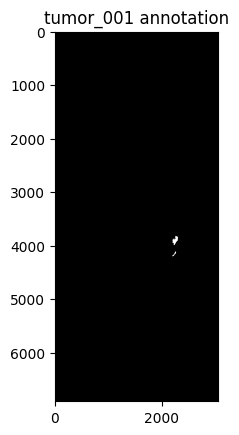

In [22]:
import matplotlib.pyplot as plt
plt.imshow(m["tumor"], cmap="gray"); plt.title("tumor_001 annotation"); plt.show()

In [23]:
import subprocess, os, time, pandas as pd
B = "s3://camelyon-dataset/CAMELYON16"

def sh(c):
    r = subprocess.run(c, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
        r.check_returncode()
    return r.stdout

df = pd.read_csv("manifest.csv")
START, END = 1, 20            # next chunks: 20,40 then 40,70
for r in df.iloc[START:END].itertuples():
    sid = r.slide_id
    if os.path.exists(f"feats/{sid}.pt"): continue
    t0 = time.time()
    sh(f"aws s3 cp --no-sign-request {B}/images/{sid}.tif /content/data/{sid}.tif --only-show-errors")
    sh(f"aws s3 cp --no-sign-request {B}/annotations/{sid}.xml /content/data/{sid}.xml --only-show-errors || true")
    xml = f"/content/data/{sid}.xml"
    pd.DataFrame([dict(slide_id=sid, path=f"/content/data/{sid}.tif",
                       xml=xml if os.path.exists(xml) else "",
                       split=r.split, label=r.label)]).to_csv("one.csv", index=False)
    out = sh("python preprocess.py --manifest one.csv --stride 512")
    sh("python extract_features.py --manifest one.csv --workers 2")
    sh(f"rm -f /content/data/{sid}.*")
    print(out.strip().splitlines()[-1], f"| {time.time()-t0:.0f}s", flush=True)

tumor_002: 749 patches, 1 tumor | 40s
tumor_003: 1229 patches, 6 tumor | 44s
tumor_004: 2332 patches, 16 tumor | 67s
tumor_005: 689 patches, 3 tumor | 32s
tumor_006: 2974 patches, 2 tumor | 70s
tumor_007: 2092 patches, 2 tumor | 55s
tumor_008: 2399 patches, 0 tumor | 66s
tumor_009: 2053 patches, 795 tumor | 63s
tumor_010: 1890 patches, 0 tumor | 53s
tumor_011: 1041 patches, 197 tumor | 38s
tumor_012: 1154 patches, 1 tumor | 39s
tumor_013: 1023 patches, 9 tumor | 36s
tumor_014: 1822 patches, 67 tumor | 49s
tumor_015: 5099 patches, 12 tumor | 106s
tumor_016: 939 patches, 153 tumor | 31s
tumor_017: 1626 patches, 0 tumor | 53s
tumor_018: 1787 patches, 47 tumor | 54s
tumor_019: 487 patches, 4 tumor | 30s
tumor_020: 1449 patches, 79 tumor | 49s


In [24]:
import numpy as np
for s in ["tumor_008", "tumor_010"]:
    m = np.load(f"patches/{s}.npz")
    print(s, "annotation pixels:", int(m["tumor"].sum()))

tumor_008 annotation pixels: 766
tumor_010 annotation pixels: 497


34228 1406 4.108% median tumor 7.5


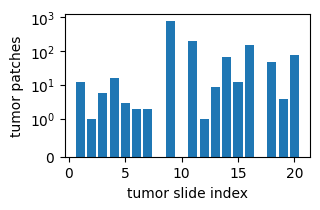

In [25]:
import numpy as np, matplotlib.pyplot as plt
ids = [f"tumor_{i:03d}" for i in range(1, 21)]
tum = [int(np.load(f"patches/{s}.npz")["labels"].sum()) for s in ids]
tot = [len(np.load(f"patches/{s}.npz")["coords"]) for s in ids]
print(sum(tot), sum(tum), f"{sum(tum)/sum(tot):.3%}", "median tumor", np.median(tum))
fig, ax = plt.subplots(figsize=(3.3, 2.2))
ax.bar(range(1, 21), tum)
ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("tumor slide index"); ax.set_ylabel("tumor patches")
plt.tight_layout(); plt.savefig("fig_tumor_per_slide.png", dpi=200)

In [26]:
import subprocess, os, time, pandas as pd
B = "s3://camelyon-dataset/CAMELYON16"

def sh(c):
    r = subprocess.run(c, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
        r.check_returncode()
    return r.stdout

df = pd.read_csv("manifest.csv")
START, END = 20, 70            # make it easier
for r in df.iloc[START:END].itertuples():
    sid = r.slide_id
    if os.path.exists(f"feats/{sid}.pt"): continue
    t0 = time.time()
    sh(f"aws s3 cp --no-sign-request {B}/images/{sid}.tif /content/data/{sid}.tif --only-show-errors")
    sh(f"aws s3 cp --no-sign-request {B}/annotations/{sid}.xml /content/data/{sid}.xml --only-show-errors || true")
    xml = f"/content/data/{sid}.xml"
    pd.DataFrame([dict(slide_id=sid, path=f"/content/data/{sid}.tif",
                       xml=xml if os.path.exists(xml) else "",
                       split=r.split, label=r.label)]).to_csv("one.csv", index=False)
    out = sh("python preprocess.py --manifest one.csv --stride 512")
    sh("python extract_features.py --manifest one.csv --workers 2")
    sh(f"rm -f /content/data/{sid}.*")
    print(out.strip().splitlines()[-1], f"| {time.time()-t0:.0f}s", flush=True)

normal_001: 378 patches, 0 tumor | 26s
normal_002: 398 patches, 0 tumor | 28s
normal_003: 969 patches, 0 tumor | 41s
normal_004: 239 patches, 0 tumor | 21s
normal_005: 337 patches, 0 tumor | 26s
normal_006: 225 patches, 0 tumor | 34s
normal_007: 610 patches, 0 tumor | 33s
normal_008: 111 patches, 0 tumor | 20s
normal_009: 1379 patches, 0 tumor | 45s
normal_010: 414 patches, 0 tumor | 29s
normal_011: 2178 patches, 0 tumor | 58s
normal_012: 637 patches, 0 tumor | 29s
normal_013: 210 patches, 0 tumor | 24s
normal_014: 404 patches, 0 tumor | 31s
normal_015: 938 patches, 0 tumor | 33s
normal_016: 72 patches, 0 tumor | 20s
normal_017: 87 patches, 0 tumor | 20s
normal_018: 601 patches, 0 tumor | 30s
normal_019: 57 patches, 0 tumor | 19s
normal_020: 107 patches, 0 tumor | 22s
test_001: 1226 patches, 96 tumor | 32s
test_002: 1488 patches, 30 tumor | 49s
test_003: 813 patches, 0 tumor | 39s
test_004: 1639 patches, 0 tumor | 41s
test_005: 619 patches, 0 tumor | 30s
test_006: 1905 patches, 0 tumor

In [27]:
!ls feats | wc -l
!aws s3 ls --no-sign-request s3://camelyon-dataset/CAMELYON16/annotations/ | grep -c test_

70
49


In [28]:
import numpy as np
print("tumor_017 annotation pixels:", int(np.load("patches/tumor_017.npz")["tumor"].sum()))

tumor_017 annotation pixels: 227


In [29]:
!python train_patch.py

20x: n_test=42192 pos=4351 acc=0.7082 auc=0.9686 f1=0.4071
10x: n_test=42192 pos=4351 acc=0.5428 auc=0.9409 f1=0.3068
20x+10x: n_test=42192 pos=4351 acc=0.6804 auc=0.9696 f1=0.3870


In [30]:
%%bash
for s in 0 1 2; do
  python train_mil.py --mode single --seed $s
  python train_mil.py --mode multi  --seed $s
done

epoch 0 val_auc 0.062
epoch 1 val_auc 0.062
epoch 2 val_auc 0.062
epoch 3 val_auc 0.125
epoch 4 val_auc 0.188
epoch 5 val_auc 0.250
epoch 6 val_auc 0.562
epoch 7 val_auc 0.625
epoch 8 val_auc 0.562
epoch 9 val_auc 0.625
epoch 10 val_auc 0.750
epoch 11 val_auc 0.688
epoch 12 val_auc 0.875
epoch 13 val_auc 0.750
epoch 14 val_auc 0.875
epoch 15 val_auc 0.688
epoch 16 val_auc 0.812
epoch 17 val_auc 0.812
epoch 18 val_auc 0.812
epoch 19 val_auc 0.812
epoch 20 val_auc 0.812
epoch 21 val_auc 0.812
epoch 22 val_auc 0.812
epoch 23 val_auc 0.812
epoch 24 val_auc 0.812
epoch 25 val_auc 0.812
epoch 26 val_auc 0.812
epoch 27 val_auc 0.812
epoch 28 val_auc 0.812
epoch 29 val_auc 0.812
epoch 30 val_auc 0.812
epoch 31 val_auc 0.812
epoch 32 val_auc 0.812
epoch 33 val_auc 0.812
epoch 34 val_auc 0.812
epoch 35 val_auc 0.812
epoch 36 val_auc 0.812
epoch 37 val_auc 0.812
epoch 38 val_auc 0.812
epoch 39 val_auc 0.812
{'tag': 'feats_single', 'seed': 0, 'val_auc': np.float64(0.875), 'test_auc': np.float64(0.

In [31]:
import json, glob, numpy as np
for tag in ["feats_single", "feats_multi"]:
    r = [json.load(open(f)) for f in sorted(glob.glob(f"results/{tag}_s*.json"))]
    a = [x["test_auc"] for x in r]; c = [x["test_acc"] for x in r]
    print(tag, f"AUC {np.mean(a):.3f} +/- {np.std(a):.3f}  acc {np.mean(c):.3f}  n_test {r[0]['n_test']}")

feats_single AUC 0.810 +/- 0.015  acc 0.600  n_test 30
feats_multi AUC 0.738 +/- 0.123  acc 0.589  n_test 30


In [32]:
import pandas as pd
df = pd.read_csv("manifest.csv")
t = df[df.split == "test"].copy()
print("test tumor slides:", int(t.label.sum()), "normal:", int((1 - t.label).sum()))

test tumor slides: 13 normal: 17


In [33]:
import numpy as np
t["tumor_patches"] = [int(np.load(f"patches/{s}.npz")["labels"].sum()) for s in t.slide_id]
for tag in ["feats_single", "feats_multi"]:
    p = pd.concat([pd.read_csv(f"results/preds_{tag}_s{s}.csv") for s in range(3)])
    m = p.merge(t[["slide_id", "tumor_patches"]], on="slide_id")
    print(tag)
    print(m[m.y == 1].groupby("slide_id").agg(tumor_patches=("tumor_patches", "first"),
                                              mean_p=("p", "mean")).sort_values("tumor_patches"))

feats_single
          tumor_patches    mean_p
slide_id                         
test_004              0  0.376313
test_013              0  0.450735
test_011              0  0.274035
test_010              0  0.405866
test_008              1  0.358841
test_029              1  0.447369
test_030              7  0.988793
test_002             30  0.743577
test_027             44  0.987430
test_001             96  0.777483
test_026            238  0.960429
test_016            659  0.848686
test_021           3275  0.968965
feats_multi
          tumor_patches    mean_p
slide_id                         
test_004              0  0.550106
test_013              0  0.783394
test_011              0  0.433690
test_010              0  0.568450
test_008              1  0.742453
test_029              1  0.356712
test_030              7  0.984059
test_002             30  0.592493
test_027             44  0.974709
test_001             96  0.878580
test_026            238  0.864568
test_016            659

In [34]:
!aws s3 cp --no-sign-request s3://camelyon-dataset/CAMELYON16/images/test_021.tif /content/data/test_021.tif --only-show-errors
!python heatmap.py test_021 feats_single

In [35]:
for tag in ["feats_single", "feats_multi"]:
    p = pd.concat([pd.read_csv(f"results/preds_{tag}_s{s}.csv") for s in range(3)])
    print(tag, p[p.y == 0].groupby("slide_id").p.mean().sort_values().round(2).to_dict())

feats_single {'test_007': 0.2, 'test_005': 0.22, 'test_024': 0.28, 'test_018': 0.29, 'test_015': 0.3, 'test_003': 0.31, 'test_028': 0.31, 'test_017': 0.32, 'test_009': 0.32, 'test_023': 0.35, 'test_019': 0.36, 'test_014': 0.4, 'test_012': 0.41, 'test_025': 0.47, 'test_006': 0.78, 'test_022': 0.85, 'test_020': 0.85}
feats_multi {'test_003': 0.08, 'test_007': 0.1, 'test_023': 0.18, 'test_024': 0.21, 'test_014': 0.38, 'test_018': 0.38, 'test_028': 0.39, 'test_005': 0.42, 'test_019': 0.46, 'test_025': 0.55, 'test_020': 0.63, 'test_015': 0.64, 'test_009': 0.67, 'test_012': 0.68, 'test_017': 0.72, 'test_006': 0.92, 'test_022': 0.95}


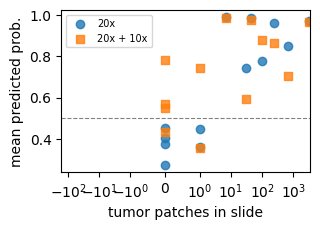

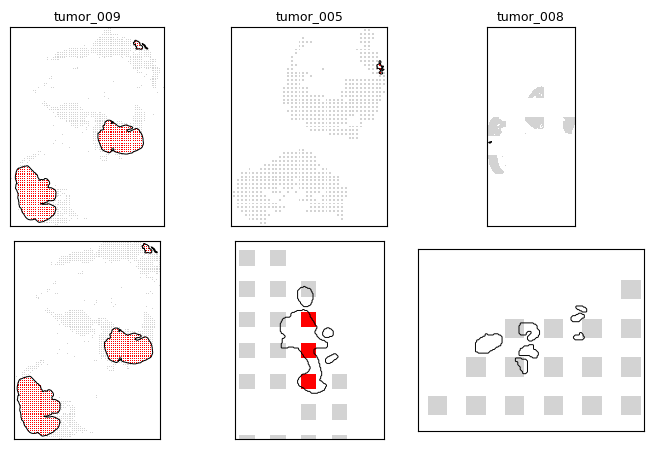

In [36]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

# Figure A: probability vs tumor patches (13 tumor test slides)
df = pd.read_csv("manifest.csv"); t = df[df.split == "test"].copy()
t["tp"] = [int(np.load(f"patches/{s}.npz")["labels"].sum()) for s in t.slide_id]
fig, ax = plt.subplots(figsize=(3.3, 2.4))
for tag, mk, name in [("feats_single", "o", "20x"), ("feats_multi", "s", "20x + 10x")]:
    p = pd.concat([pd.read_csv(f"results/preds_{tag}_s{s}.csv") for s in range(3)])
    g = p.groupby("slide_id").agg(y=("y", "first"), p=("p", "mean")).join(t.set_index("slide_id").tp)
    pos = g[g.y == 1]
    ax.scatter(pos.tp, pos.p, marker=mk, label=name, alpha=0.8)
ax.axhline(0.5, color="gray", ls="--", lw=0.8)
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("tumor patches in slide"); ax.set_ylabel("mean predicted prob.")
ax.legend(fontsize=7); plt.tight_layout(); plt.savefig("fig_prob_vs_patches.png", dpi=200)

# Figure B: patch grid vs annotation
def draw(ax, sid, zoom):
    m = np.load(f"patches/{sid}.npz")
    ds = float(m["mds"]); sz = float(m["size0"]) / ds
    xy = m["coords"] / ds; lab = m["labels"].astype(bool); tum = m["tumor"]
    cols = ["red" if l else "lightgray" for l in lab]
    ax.add_collection(PatchCollection([Rectangle(q, sz, sz) for q in xy], facecolors=cols, edgecolors="none"))
    if tum.any(): ax.contour(tum, levels=[0.5], colors="black", linewidths=0.7)
    if zoom:
        ys, xs = np.nonzero(tum); pad = 3 * sz
        ax.set_xlim(xs.min() - pad, xs.max() + pad); ax.set_ylim(ys.max() + pad, ys.min() - pad)
    else:
        ax.set_xlim(xy[:, 0].min() - sz, xy[:, 0].max() + 2 * sz); ax.set_ylim(xy[:, 1].max() + 2 * sz, xy[:, 1].min() - sz)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

fig, axs = plt.subplots(2, 3, figsize=(7, 4.6))
for j, sid in enumerate(["tumor_009", "tumor_005", "tumor_008"]):
    draw(axs[0, j], sid, False); draw(axs[1, j], sid, True)
    axs[0, j].set_title(sid, fontsize=9)
plt.tight_layout(); plt.savefig("fig_patch_grid.png", dpi=200)